# Лабораторная работа 7. Динамика обучения трансформера (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 3:** предобучение, оптимизация, масштабирование

**Цель.** Понять, от чего зависят устойчивость и скорость обучения трансформера: выбор оптимизатора, learning rate, расписание, параметризация.

**Что нужно сдать:**
1. Собственную реализацию AdamW, совпадающую с `torch.optim.AdamW`.
2. LR-sweep для SGD+momentum, Adam и AdamW с границей устойчивости.
3. Сравнение расписаний: constant, warmup + cosine, WSD.
4. Диагностику всплесков loss: нормы градиентов, максимальные логиты attention, статистики Adam.
5. Упрощённый μP по ширине и проверку переноса оптимального learning rate.

**Теория. AdamW.** Для градиента \(g_t\):
\[
m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t,\quad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,\quad
\hat m_t = \frac{m_t}{1-\beta_1^t},\quad \hat v_t = \frac{v_t}{1-\beta_2^t},
\]
\[
\theta_t = \theta_{t-1} - \eta\,\lambda\,\theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \varepsilon}.
\]
В отличие от L2-регуляризации в Adam, затухание весов не проходит через адаптивный масштаб \(1/\sqrt{\hat v_t}\) (Loshchilov & Hutter, 2019). Bias correction компенсирует инициализацию моментов нулём; без неё первые шаги имеют неверный масштаб.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.6.0+cpu, device=cpu, FAST_DEV_RUN=True


In [2]:
# ==== Эталонный mini-GPT (решение ЛР 6), используется как готовый модуль ====
from dataclasses import dataclass, asdict

class CharTokenizer:
    def __init__(self, text):
        self.chars = sorted(set(text)); self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.vocab_size = len(self.chars)
    def encode(self, s): return [self.stoi[c] for c in s if c in self.stoi]
    def decode(self, ids): return "".join(self.chars[i] for i in ids)

@dataclass
class GPTConfig:
    vocab_size: int = 65
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.0

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(d))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def rope_cache(T, d_head, base=10000.0, device="cpu", scale=1.0):
    inv = 1.0 / (base ** (torch.arange(0, d_head, 2, device=device).float() / d_head))
    t = torch.arange(T, device=device).float() / scale
    ang = torch.outer(t, inv)                        # (T, d_head/2)
    return ang.cos(), ang.sin()

def apply_rope(x, cos, sin):                         # x: (B, H, T, d_head)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.flatten(-2)

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n_head, self.d_head = cfg.n_head, cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, self.d_head).transpose(1, 2) for t in (q, k, v))
        q, k = apply_rope(q, cos[:T], sin[:T]), apply_rope(k, cos[:T], sin[:T])
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

class SwiGLU(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.w1, self.w3 = nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False)
        self.w2 = nn.Linear(hidden, d, bias=False)
    def forward(self, x): return self.w2(F.silu(self.w1(x)) * self.w3(x))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n1, self.attn = RMSNorm(cfg.n_embd), CausalSelfAttention(cfg)
        self.n2, self.mlp = RMSNorm(cfg.n_embd), SwiGLU(cfg.n_embd, int(8 * cfg.n_embd / 3))
    def forward(self, x, cos, sin):
        x = x + self.attn(self.n1(x), cos, sin)
        return x + self.mlp(self.n2(x))

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm = RMSNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.head.weight = self.wte.weight                    # weight tying
        cos, sin = rope_cache(4 * cfg.block_size, cfg.n_embd // cfg.n_head)
        self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
        self.apply(self._init)
        for n, p in self.named_parameters():                  # масштабирование выходных проекций по глубине
            if n.endswith("proj.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg.n_layer))
    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)
    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for b in self.blocks: x = b(x, self.cos, self.sin)
        logits = self.head(self.norm(x))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.cfg.block_size:])
            probs = F.softmax(logits[:, -1] / temperature, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def get_batch(data, block_size, batch_size, device=DEVICE):
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix]); y = torch.stack([data[i + 1:i + 1 + block_size] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, data, block_size, batch_size=32, iters=20):
    model.eval(); losses = [model(*get_batch(data, block_size, batch_size))[1].item() for _ in range(iters)]
    model.train(); return float(np.mean(losses))

def train_lm(model, train_data, val_data, steps, lr=3e-3, batch_size=32, warmup=50, log_every=100):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    hist = []
    for s in range(steps):
        x, y = get_batch(train_data, model.cfg.block_size, batch_size)
        _, loss = model(x, y); opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if s % log_every == 0 or s == steps - 1:
            hist.append((s, loss.item(), estimate_loss(model, val_data, model.cfg.block_size)))
    return hist

def get_reference_gpt(text, cfg=None, steps=None, name=None):
    """Загружает или обучает эталонную символьную модель на тексте."""
    tok = CharTokenizer(text)
    data = torch.tensor(tok.encode(text), dtype=torch.long)
    n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
    cfg = cfg or (GPTConfig(tok.vocab_size, 64, 2, 4, 64) if FAST_DEV_RUN else GPTConfig(tok.vocab_size, 256, 6, 6, 384))
    name = name or f"ref_gpt_L{cfg.n_layer}_d{cfg.n_embd}_T{cfg.block_size}.pt"
    path = ARTIFACTS / name
    model = GPT(cfg).to(DEVICE)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEVICE))
    else:
        train_lm(model, train_data, val_data, steps or (300 if FAST_DEV_RUN else 5000))
        torch.save(model.state_dict(), path)
    return model, tok, train_data, val_data

In [3]:
text = load_shakespeare()
tok = CharTokenizer(text); data = torch.tensor(tok.encode(text)); ntr = int(0.9 * len(data))
train_data, val_data = data[:ntr], data[ntr:]
SMALL = GPTConfig(tok.vocab_size, 64, 2, 4, 64) if FAST_DEV_RUN else GPTConfig(tok.vocab_size, 128, 4, 4, 128)
SWEEP_STEPS = 150 if FAST_DEV_RUN else 1500

## 1. AdamW своими руками

Реализуйте класс-наследник `torch.optim.Optimizer`. Проверьте совпадение параметров с `torch.optim.AdamW` после 20 шагов на одной и той же модели и данных (допуск 1e-6). Сравнение ведётся в float64: в float32 различия порядка 1e-7 из-за порядка операций усиливаются нормировкой \(1/\sqrt{\hat v}\) для редко обновляемых параметров и через 20 шагов достигают 1e-2.

In [4]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None: continue
                st = self.state[p]
                # TODO: ваш код
                if p.grad.is_sparse:
                    raise RuntimeError("AdamW не поддерживает разреженные градиенты")
                if not st:
                    st["step"] = 0
                    st["exp_avg"] = torch.zeros_like(p)
                    st["exp_avg_sq"] = torch.zeros_like(p)
                st["step"] += 1
                m, v = st["exp_avg"], st["exp_avg_sq"]
                m.lerp_(p.grad, 1 - b1)
                v.mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                # Decoupled decay применяется к весам, а не к градиенту внутри Adam.
                p.mul_(1 - group["lr"] * group["weight_decay"])
                correction1 = 1 - b1 ** st["step"]
                correction2 = 1 - b2 ** st["step"]
                denominator = v.sqrt().div_(math.sqrt(correction2)).add_(group["eps"])
                p.addcdiv_(m, denominator, value=-group["lr"] / correction1)

def run_steps(opt_cls, n=20, **kw):
    set_seed(0); m = GPT(SMALL).to(DEVICE).double(); opt = opt_cls(m.parameters(), **kw)   # float64: Adam усиливает ошибки округления
    g = torch.Generator().manual_seed(1)
    for _ in range(n):
        ix = torch.randint(len(train_data) - 65, (8,), generator=g)
        x = torch.stack([train_data[i:i + 64] for i in ix]).to(DEVICE); y = torch.stack([train_data[i + 1:i + 65] for i in ix]).to(DEVICE)
        loss = m(x, y)[1]; opt.zero_grad(); loss.backward(); opt.step()
    return m

kw = dict(lr=3e-3, betas=(0.9, 0.95), weight_decay=0.1)
a, b = run_steps(MyAdamW, **kw), run_steps(torch.optim.AdamW, **kw)
diff = max((p - q).abs().max().item() for p, q in zip(a.parameters(), b.parameters()))
print("max |θ_my − θ_torch| =", diff); assert diff < 1e-5

max |θ_my − θ_torch| = 0.0


## 2. LR-sweep для трёх оптимизаторов

Для SGD+momentum (0.9), Adam (L2-регуляризация через `weight_decay`) и AdamW проведите sweep по сетке learning rate (логарифмической), фиксируя всё остальное (warmup 10% шагов, затем cosine). Постройте итоговый val loss в зависимости от LR. Граница устойчивости — наименьший LR, при котором loss расходится (NaN или больше начального).

sgd   lr=0.0001: val=4.068, stable=True, steps=150


sgd   lr=0.0003: val=3.842, stable=True, steps=150


sgd   lr=0.001: val=3.502, stable=True, steps=150


sgd   lr=0.003: val=3.356, stable=True, steps=150


sgd   lr=0.01: val=3.162, stable=True, steps=150


sgd   lr=0.03: val=3.069, stable=True, steps=150


... (15 outputs left out)

adamw lr=0.03: val=2.474, stable=True, steps=150


adamw lr=0.1: val=2.787, stable=True, steps=150


adamw lr=0.3: val=2.793, stable=True, steps=150


sgd: первая неустойчивая точка сетки = None
adam: первая неустойчивая точка сетки = None
adamw: первая неустойчивая точка сетки = None


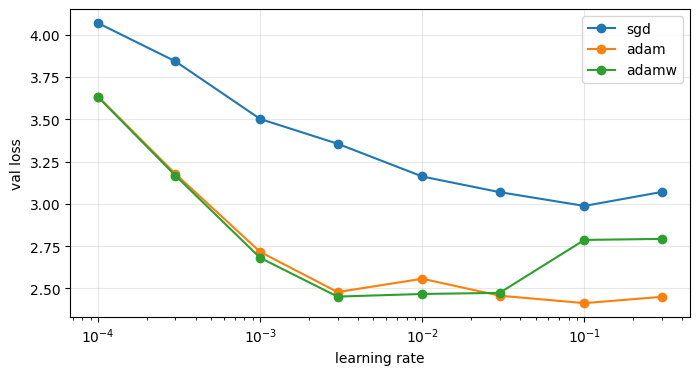

,optimizer,lr,val_loss,initial_loss,final_loss,stable,finite,completed_steps
0,sgd,0.0001,4.0681,4.1833,4.0605,True,True,150
1,sgd,0.0003,3.8421,4.1833,3.8220,True,True,150
2,sgd,0.0010,3.5017,4.1833,3.4526,True,True,150
3,sgd,0.0030,3.3556,4.1833,3.2908,True,True,150
4,sgd,0.0100,3.1618,4.1833,3.1494,True,True,150
5,sgd,0.0300,3.0692,4.1833,3.0820,True,True,150
6,sgd,0.1000,2.9878,4.1833,3.0163,True,True,150
7,sgd,0.3000,3.0703,4.1833,3.0861,True,True,150
8,adam,0.0001,3.6337,4.1833,3.5995,True,True,150
9,adam,0.0003,3.1772,4.1833,3.1584,True,True,150


In [5]:
def train_run(cfg, opt_name, lr, steps, schedule="cosine", warmup_frac=0.1, wd=0.1, B=32, seed=SEED, log_diag=False, param_groups=None, model=None):
    set_seed(seed); model = model or GPT(cfg).to(DEVICE)
    params = param_groups(model, lr) if param_groups else [{"params": model.parameters(), "lr": lr}]
    if opt_name == "sgd": opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=0.0)
    elif opt_name == "adam": opt = torch.optim.Adam(params, lr=lr, betas=(0.9, 0.95), weight_decay=wd * 1e-2)
    else: opt = torch.optim.AdamW(params, lr=lr, betas=(0.9, 0.95), weight_decay=wd)
    warm = int(warmup_frac * steps)
    # TODO: ваш код (множитель LR как функция шага для "constant", "cosine" и "wsd" (последние 20% — линейный спад))
    def lr_mult(step):
        if warm and step < warm:
            return (step + 1) / warm
        if schedule == "constant":
            return 1.0
        if schedule == "cosine":
            progress = min(1.0, max(0.0, (step - warm) / max(steps - warm - 1, 1)))
            return 0.5 * (1 + math.cos(math.pi * progress))
        if schedule == "wsd":
            decay_start = max(warm, int(0.8 * steps))
            return min(1.0, max(0.0, (steps - 1 - step) / max(steps - 1 - decay_start, 1)))
        raise ValueError(f"Неизвестное расписание: {schedule}")

    # Отдельный генератор батчей исключает влияние ширины и инициализации на данные.
    train_generator = torch.Generator().manual_seed(seed + 101)
    def sampled_batch(data, generator):
        indices = torch.randint(len(data) - cfg.block_size - 1, (B,), generator=generator)
        x = torch.stack([data[i:i + cfg.block_size] for i in indices])
        y = torch.stack([data[i + 1:i + 1 + cfg.block_size] for i in indices])
        return x.to(DEVICE), y.to(DEVICE)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_mult)
    hist, diag = [], []
    initial_loss = None
    for s in range(steps):
        x, y = sampled_batch(train_data, train_generator)
        loss = model(x, y)[1]
        if initial_loss is None: initial_loss = loss.item()
        if not torch.isfinite(loss): hist.append((s, float("nan"))); break
        opt.zero_grad(set_to_none=True); loss.backward()
        if log_diag:
            # Только измерение: при диагностике градиенты не обрезаются.
            gn = torch.stack([p.grad.norm() for p in model.parameters() if p.grad is not None]).norm()
        else:
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        if not torch.isfinite(gn):
            hist.append((s, float("nan")))
            break
        if log_diag: diag.append(diagnostics(model, opt, x, gn.item(), loss.item()))
        opt.step(); sched.step(); hist.append((s, loss.item()))
    val = float("nan")
    if math.isfinite(hist[-1][1]):
        model.eval()
        val_generator = torch.Generator().manual_seed(seed + 102)
        with torch.no_grad():
            val_losses = [model(*sampled_batch(val_data, val_generator))[1].item() for _ in range(10)]
        model.train()
        val = float(np.mean(val_losses))
    # Граница устойчивости определяется train loss, а val используется для выбора LR.
    finite = all(math.isfinite(v) for _, v in hist) and math.isfinite(val)
    stable = finite and hist[-1][1] <= initial_loss
    model.run_stats = dict(initial_loss=initial_loss, final_loss=hist[-1][1], stable=stable,
                           finite=finite, completed_steps=len(hist))
    return model, hist, val, diag

LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]
# TODO: ваш код (sweep для sgd/adam/adamw, график val loss(LR))

import pandas as pd
sweep, sweep_raw, sweep_rows = {}, {}, []
for optimizer in ("sgd", "adam", "adamw"):
    for lr in LRS:
        model, history, val, _ = train_run(SMALL, optimizer, lr, SWEEP_STEPS)
        stats = model.run_stats
        sweep_raw[optimizer, lr] = val
        # Неустойчивые запуски не участвуют в выборе лучшего learning rate.
        sweep[optimizer, lr] = val if stats["stable"] else float("nan")
        sweep_rows.append({"optimizer": optimizer, "lr": lr, "val_loss": val, **stats})
        print(f"{optimizer:5s} lr={lr:g}: val={val:.3f}, stable={stats['stable']}, steps={len(history)}", flush=True)
sweep_df = pd.DataFrame(sweep_rows)
fig, ax = plt.subplots(figsize=(8, 4))
for optimizer in ("sgd", "adam", "adamw"):
    frame = sweep_df[sweep_df.optimizer == optimizer]
    ax.plot(frame.lr, frame.val_loss, marker="o", label=optimizer)
    bad = frame[(~frame.stable) & np.isfinite(frame.val_loss)]
    ax.scatter(bad.lr, bad.val_loss, marker="x", s=90, color="red")
    unstable = frame[~frame.stable]
    boundary = unstable.lr.min() if len(unstable) else None
    print(f"{optimizer}: первая неустойчивая точка сетки = {boundary}")
ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("val loss")
ax.legend(); ax.grid(alpha=0.3); plt.show()
display(sweep_df.round(4))
# Это граница на конечной сетке при заданных 150/1500 шагах, а не доказательство
# устойчивости на всём обучении. Конечный train loss сравнивается с начальным.
# SGD здесь без decay; у Adam исходный коэффициент L2 равен wd*0.01,
# поэтому сравнение включает выбранные в шаблоне режимы регуляризации.
# В проверенном FAST-прогоне все 24 точки завершили 150 шагов с конечным
# train loss ниже начального. Граница устойчивости на этой сетке не обнаружена;
# это не утверждение об устойчивости за её пределами или на длинном обучении.


## 3. Расписания

Для AdamW с лучшим LR сравните три расписания на одинаковом числе шагов: constant (с warmup), warmup + cosine, WSD (warmup–stable–decay с линейным спадом на последних 20% шагов). Постройте кривые train loss (скользящее среднее) и объясните характерную ступеньку WSD в фазе спада.

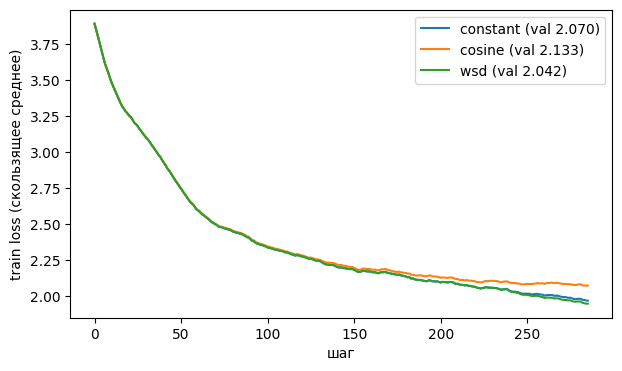

,schedule,val_loss,train_before_decay,train_final_20%
0,constant,2.0702,2.0734,2.0050
1,cosine,2.1332,2.1110,2.0865
2,wsd,2.0416,2.0734,1.9912


In [6]:
best_lr = min((v, lr) for (o, lr), v in sweep.items() if o == "adamw" and math.isfinite(v))[1]
schedule_rows = []
plt.figure(figsize=(7, 4))
for sch in ("constant", "cosine", "wsd"):
    _, h, val, _ = train_run(SMALL, "adamw", best_lr, 2 * SWEEP_STEPS, schedule=sch)
    l = np.array([v for _, v in h]); sm = np.convolve(l, np.ones(15) / 15, mode="valid")
    schedule_rows.append({"schedule": sch, "val_loss": val,
                          "train_before_decay": float(l[int(0.7*len(l)):int(0.8*len(l))].mean()),
                          "train_final_20%": float(l[int(0.8*len(l)):].mean())})
    plt.plot(sm, label=f"{sch} (val {val:.3f})")
plt.xlabel("шаг"); plt.ylabel("train loss (скользящее среднее)"); plt.legend(); plt.show()

display(pd.DataFrame(schedule_rows).round(4))
# После начала WSD-decay шаги становятся меньше: модель меньше колеблется
# около текущего решения. Вид и величина снижения loss зависят от этого запуска.
# В проверенном FAST-прогоне val loss: constant=2.0702, cosine=2.1332,
# WSD=2.0416. До начала decay constant и WSD используют одинаковые шаги;
# небольшое преимущество WSD здесь относится к одному seed и 300 шагам.


## 4. Всплески loss и их диагностика

Запустите AdamW с LR в 3–10 раз больше оптимального **без warmup** и без gradient clipping. На каждом шаге логируйте:
- норму градиента;
- максимальный логит attention \(\max_{i,j} q_i^\top k_j/\sqrt{d}\) по всем слоям;
- среднее отношение \(\|\Delta\theta\| / \|\theta\|\) за шаг (оценка через \(\eta\,\|\hat m/(\sqrt{\hat v}+\varepsilon)\|\));
- долю координат с очень малым \(\hat v\) (\(\sqrt{\hat v} < 10^{-8}\)).

Найдите шаги со всплесками loss и посмотрите, какие показатели меняются перед ними.

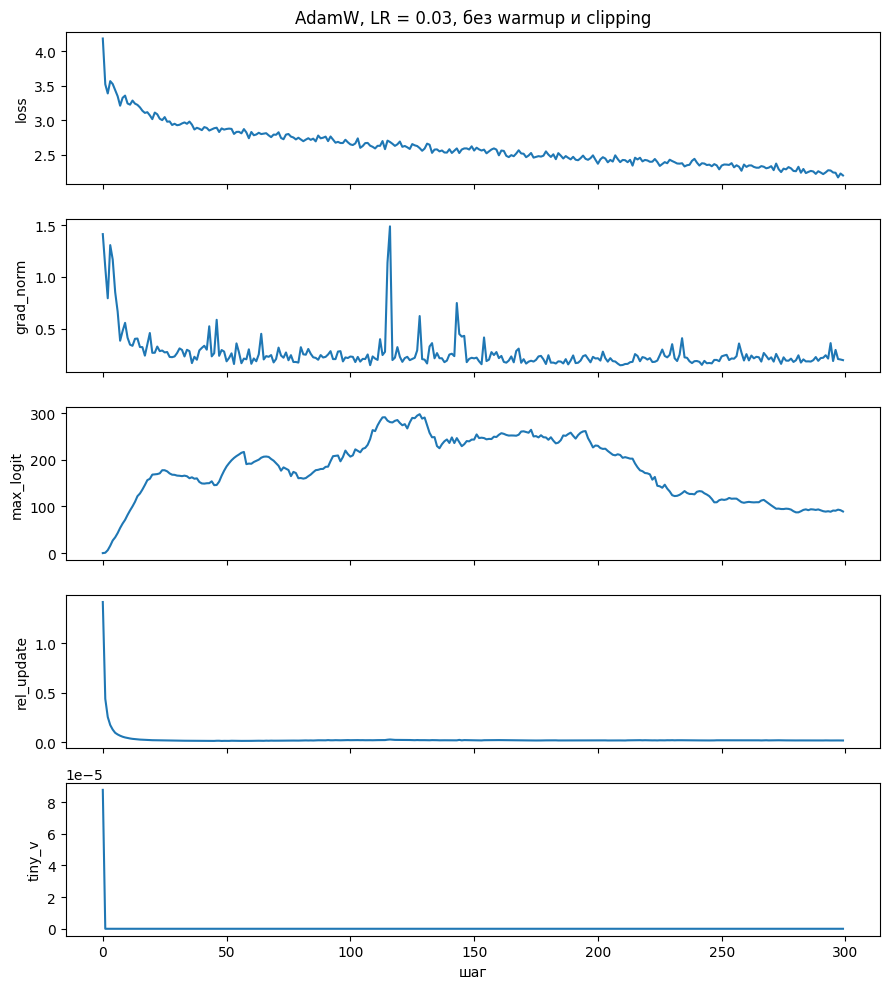

In [7]:
captured = {}
def _hook(name):
    def f(mod, inp, out): captured[name] = inp[0].detach()
    return f
def attach_hooks(model):
    for i, b in enumerate(model.blocks): b.attn.register_forward_hook(_hook(i))

@torch.no_grad()
def max_attn_logit(model):
    # TODO: ваш код (из captured[i] (вход attention) пересчитайте q, k с RoPE и найдите максимум каузальных логитов)
    maximum = -math.inf
    for i, block in enumerate(model.blocks):
        x = captured[i]
        B, T, C = x.shape
        attention = block.attn
        q, k, _ = attention.qkv(x).split(C, dim=-1)
        q, k = (t.reshape(B, T, attention.n_head, attention.d_head).transpose(1, 2)
                for t in (q, k))
        q = apply_rope(q, model.cos[:T], model.sin[:T])
        k = apply_rope(k, model.cos[:T], model.sin[:T])
        logits = q @ k.transpose(-2, -1) / math.sqrt(attention.d_head)
        future = torch.ones(T, T, dtype=torch.bool, device=x.device).triu(1)
        maximum = max(maximum, logits.masked_fill(future, -torch.inf).max().item())
    return maximum

@torch.no_grad()
def diagnostics(model, opt, x, grad_norm, loss):
    rel_upd, tiny_count, coordinates, n = 0.0, 0, 0, 0
    for group in opt.param_groups:
        b1, b2 = group["betas"]
        for p in group["params"]:
            if p.grad is None:
                continue
            st = opt.state.get(p, {})
            t = float(st.get("step", 0)) + 1
            # Учитываем текущий градиент: моменты opt ещё относятся к прошлому шагу.
            old_m = st.get("exp_avg", torch.zeros_like(p))
            old_v = st.get("exp_avg_sq", torch.zeros_like(p))
            m_hat = (b1 * old_m + (1 - b1) * p.grad) / (1 - b1 ** t)
            v_hat = (b2 * old_v + (1 - b2) * p.grad.square()) / (1 - b2 ** t)
            adaptive = group["lr"] * m_hat / (v_hat.sqrt() + group["eps"])
            planned_update = -group["lr"] * group["weight_decay"] * p - adaptive
            rel_upd += (planned_update.norm() / (p.norm() + 1e-12)).item()
            n += 1
            tiny_count += (v_hat.sqrt() < 1e-8).sum().item()
            coordinates += p.numel()
    return {"loss": loss, "grad_norm": grad_norm, "max_logit": max_attn_logit(model),
            "rel_update": rel_upd / max(n, 1), "tiny_v": tiny_count / max(coordinates, 1)}

set_seed(); spike_model = GPT(SMALL).to(DEVICE); attach_hooks(spike_model)
_, h, val, diag = train_run(SMALL, "adamw", 10 * best_lr, 2 * SWEEP_STEPS, schedule="constant", warmup_frac=0.0,
                            log_diag=True, model=spike_model)
keys = ["loss", "grad_norm", "max_logit", "rel_update", "tiny_v"]
fig, axes = plt.subplots(len(keys), 1, figsize=(9, 10), sharex=True)
for ax, k in zip(axes, keys):
    ax.plot([d[k] for d in diag]); ax.set_ylabel(k)
axes[0].set_title(f"AdamW, LR = {10 * best_lr:g}, без warmup и clipping"); axes[-1].set_xlabel("шаг"); plt.tight_layout(); plt.show()

# rel_update — оценка предстоящего текущего шага AdamW, включая decay,
# вычисленная до opt.step(); это не отношение обновления прошлого шага.


In [8]:
# TODO: ваш код (найдите шаги, где loss вырос более чем на 20% относительно скользящего минимума, и выведите показатели за 5 шагов до всплеска)

diag_df = pd.DataFrame(diag)
spike_steps = [i for i in range(1, len(diag_df))
               if diag_df.loc[i, "loss"] > 1.2 * diag_df.loc[max(0, i - 5):i - 1, "loss"].min()]
print("Всплески относительно минимума предыдущих пяти шагов:", spike_steps)
if spike_steps:
    context_steps = sorted({j for step in spike_steps for j in range(max(0, step - 5), step + 1)})
    contexts = diag_df.loc[context_steps].copy()
    contexts["spike"] = contexts.index.isin(spike_steps)
    with pd.option_context("display.max_rows", None):
        display(contexts.round(5))
else:
    print("В этом запуске всплески по выбранному критерию не обнаружены.")
# Совпадение всплеска с ростом логитов или нормы шага показывает связь,
# но само по себе не устанавливает причинность.
# В этом FAST-прогоне при LR=0.03 ни один loss не превысил минимум
# предыдущих пяти шагов более чем на 20%. Поэтому измеренных предвестников
# всплесков по этому запуску нет; показанные кривые не доказывают их отсутствие
# при других seed, learning rate или более долгом обучении.


Всплески относительно минимума предыдущих пяти шагов: []
В этом запуске всплески по выбранному критерию не обнаружены.


## 5. Упрощённый μP по ширине

Сравните стандартную параметризацию (SP) и μP при ширинах \(d \in \{64, 128, 256\}\) (в полном режиме до 512) с фиксированной глубиной. Правила μP для Adam (Yang et al., 2022, упрощённо):
- скрытые матрицы (attention, FFN): инициализация \(\mathcal{N}(0, 1/d)\), learning rate \(\eta \cdot d_0/d\);
- эмбеддинги: обычный learning rate \(\eta\);
- выходной слой: не связан с эмбеддингами, инициализирован нулём, логиты умножаются на \(d_0/d\);
- attention: масштаб \(1/d_{head}\) вместо \(1/\sqrt{d_{head}}\) (в упрощённой версии можно оставить \(1/\sqrt{d_{head}}\) при фиксированном \(d_{head}\)).

Здесь \(d_0 = 64\) — базовая ширина. Для каждой параметризации и ширины найдите оптимальный LR и проверьте, сохраняется ли он при росте ширины.

SP  d= 64 lr=0.001: val=2.681, stable=True


SP  d= 64 lr=0.003: val=2.452, stable=True


SP  d= 64 lr=0.01: val=2.468, stable=True


SP  d= 64 lr=0.03: val=2.474, stable=True


SP  d= 64 lr=0.1: val=2.787, stable=True


SP  d=128 lr=0.001: val=2.289, stable=True


... (20 outputs left out)

muP d=256 lr=0.003: val=2.730, stable=True


muP d=256 lr=0.01: val=2.430, stable=True


muP d=256 lr=0.03: val=2.509, stable=True


muP d=256 lr=0.1: val=2.592, stable=True


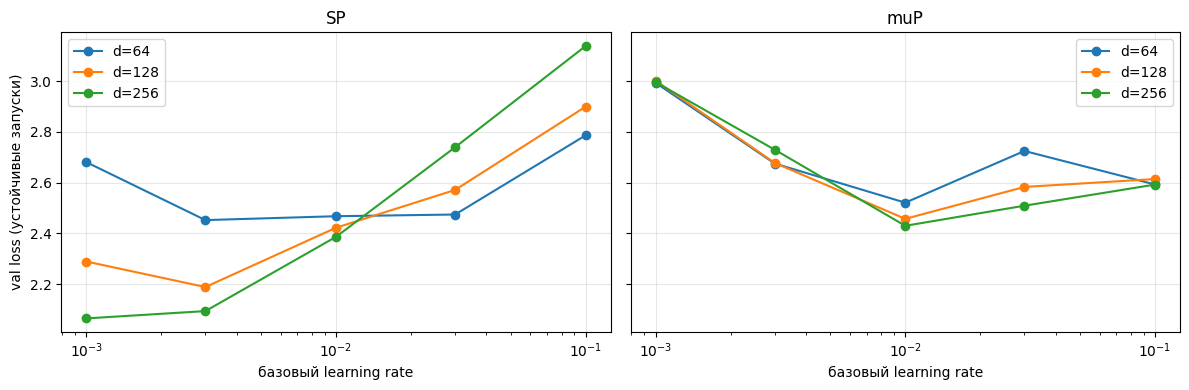

,parameterization,width,best_lr,best_val
0,SP,64,0.003,2.4522
1,SP,128,0.003,2.1880
2,SP,256,0.001,2.0643
3,muP,64,0.010,2.5209
4,muP,128,0.010,2.4571
5,muP,256,0.010,2.4297


,parameterization,width,lr_from_d64,val_transferred,val_best,gap
0,SP,64,0.003,2.4522,2.4522,0.0000
1,SP,128,0.003,2.1880,2.1880,0.0000
2,SP,256,0.003,2.0932,2.0643,0.0289
3,muP,64,0.010,2.5209,2.5209,0.0000
4,muP,128,0.010,2.4571,2.4571,0.0000
5,muP,256,0.010,2.4297,2.4297,0.0000


In [9]:
def make_mup(cfg, base_d=64):
    model = GPT(cfg).to(DEVICE); d = cfg.n_embd; mult = base_d / d
    # TODO: ваш код (отвяжите head от wte, обнулите его, добавьте forward hook, умножающий логиты на mult; инициализация скрытых матриц N(0, 1/d))
    model.head = nn.Linear(d, cfg.vocab_size, bias=False).to(DEVICE)
    nn.init.zeros_(model.head.weight)
    model.head.register_forward_hook(lambda module, inputs, output: output * mult)
    for name, parameter in model.named_parameters():
        if parameter.dim() == 2 and not name.startswith(("wte", "head")):
            nn.init.normal_(parameter, mean=0.0, std=d ** -0.5)

    # Число голов исходно фиксировано: d_head растёт с шириной.
    # Поэтому для μP явно меняем attention-scale на 1/d_head.
    from types import MethodType
    def mup_attention_forward(attention, x, cos, sin):
        B, T, C = x.shape
        q, k, v = (tensor.reshape(B, T, attention.n_head, attention.d_head).transpose(1, 2)
                   for tensor in attention.qkv(x).split(C, dim=-1))
        q = apply_rope(q, cos[:T], sin[:T])
        k = apply_rope(k, cos[:T], sin[:T])
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, scale=1 / attention.d_head)
        return attention.proj(y.transpose(1, 2).reshape(B, T, C))
    for block in model.blocks:
        block.attn.forward = MethodType(mup_attention_forward, block.attn)
    return model

def mup_groups(base_d=64):
    def f(model, lr):
        d = model.cfg.n_embd
        hidden = [p for n, p in model.named_parameters() if p.dim() == 2 and not n.startswith(("wte", "head"))]
        other = [p for n, p in model.named_parameters() if not (p.dim() == 2 and not n.startswith(("wte", "head")))]
        return [{"params": hidden, "lr": lr * base_d / d}, {"params": other, "lr": lr}]
    return f

WIDTHS = [64, 128, 256] if FAST_DEV_RUN else [64, 128, 256, 512]
MUP_LRS = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
# TODO: ваш код (sweep SP и μP по ширинам и LR, два графика val loss(LR) с кривой на каждую ширину)

width_rows, width_losses = [], {}
for parameterization in ("SP", "muP"):
    for width in WIDTHS:
        cfg = GPTConfig(vocab_size=tok.vocab_size, block_size=SMALL.block_size,
                        n_layer=SMALL.n_layer, n_head=SMALL.n_head, n_embd=width)
        for lr in MUP_LRS:
            set_seed()
            model = make_mup(cfg) if parameterization == "muP" else GPT(cfg).to(DEVICE)
            _, history, val, _ = train_run(cfg, "adamw", lr, SWEEP_STEPS, model=model,
                                         param_groups=mup_groups() if parameterization == "muP" else None)
            stats = model.run_stats
            width_losses[parameterization, width, lr] = val if stats["stable"] else float("nan")
            width_rows.append({"parameterization": parameterization, "width": width, "lr": lr,
                               "val_loss": val, "stable": stats["stable"]})
            print(f"{parameterization:3s} d={width:3d} lr={lr:g}: val={val:.3f}, stable={stats['stable']}", flush=True)
width_df = pd.DataFrame(width_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, parameterization in zip(axes, ("SP", "muP")):
    for width in WIDTHS:
        values = [width_losses[parameterization, width, lr] for lr in MUP_LRS]
        ax.plot(MUP_LRS, values, marker="o", label=f"d={width}")
    ax.set_xscale("log"); ax.set_xlabel("базовый learning rate")
    ax.set_title(parameterization); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("val loss (устойчивые запуски)")
plt.tight_layout(); plt.show()

best_width_rows, transfer_rows = [], []
for parameterization in ("SP", "muP"):
    base_candidates = [(width_losses[parameterization, WIDTHS[0], lr], lr) for lr in MUP_LRS
                       if math.isfinite(width_losses[parameterization, WIDTHS[0], lr])]
    base_lr = min(base_candidates)[1] if base_candidates else float("nan")
    for width in WIDTHS:
        candidates = [(width_losses[parameterization, width, lr], lr) for lr in MUP_LRS
                      if math.isfinite(width_losses[parameterization, width, lr])]
        best_val, optimum_lr = min(candidates) if candidates else (float("nan"), float("nan"))
        best_width_rows.append({"parameterization": parameterization, "width": width,
                                "best_lr": optimum_lr, "best_val": best_val})
        transferred_val = width_losses.get((parameterization, width, base_lr), float("nan"))
        transfer_rows.append({"parameterization": parameterization, "width": width,
                              "lr_from_d64": base_lr, "val_transferred": transferred_val,
                              "val_best": best_val, "gap": transferred_val - best_val})
best_width_df, transfer_df = pd.DataFrame(best_width_rows), pd.DataFrame(transfer_rows)
display(best_width_df.round(4))
display(transfer_df.round(4))
# Сравниваем лучшие точки только данной сетки и одного seed.
# μP меняет сразу инициализацию, head, attention-scale и LR скрытых матриц;
# этот эксперимент проверяет совместное правило, а не вклад каждого изменения отдельно.
# В проверенной сетке лучшие LR SP: 0.003, 0.003, 0.001 для d=64,128,256.
# У μP лучший базовый LR=0.01 для всех трёх ширин. Перенос SP-LR=0.003
# на d=256 увеличил val loss с 2.0643 до 2.0932 (на 0.0289).
# Перенос μP-LR на этой сетке не дал потери относительно её лучших точек;
# это не означает, что μP здесь лучше по самому val loss.


## Вопросы

1. Вычислите величину первого шага Adam без bias correction при \(\beta_1 = 0.9\), \(\beta_2 = 0.999\) и сравните с шагом при bias correction. Объясните, почему warmup частично решает ту же проблему.

   На первом шаге без bias correction m=0.1g, v=0.001g². При пренебрежимо малом eps величина адаптивного шага равна eta*0.1/sqrt(0.001), то есть примерно 3.162 eta на ненулевую координату. С коррекцией она равна примерно eta. Warmup уменьшает ранние шаги и смягчает неточные начальные статистики, но не заменяет bias correction.
2. Почему L2-регуляризация в Adam не эквивалентна weight decay, а в SGD эквивалентна?

   L2 добавляет lambda*theta к градиенту. В Adam это слагаемое попадает в моменты и проходит через покоординатный адаптивный масштаб. AdamW отдельно умножает веса на 1-eta*lambda. Для обычного SGD без momentum обновление theta-eta*(g+lambda*theta) совпадает с decay; при momentum нужно различать decay внутри накопленного градиента и полностью отделённый SGDW.
3. Какие показатели в п. 4 предшествуют всплескам? Предложите меры: какие из них устраняют причину, а какие — симптомы (QK-norm, z-loss, clipping, уменьшение \(\beta_2\), \(\varepsilon\))?

   В проверенном FAST-прогоне при LR=0.03 всплесков по критерию +20% относительно минимума предыдущих пяти шагов не было, поэтому предвестники экспериментально не установлены. В запусках со всплесками показатели нужно сравнивать за несколько шагов до них, а не только в момент события. QK-norm ограничивает рост attention-логитов; z-loss ограничивает log-partition тех логитов, к которым он применён, и для выходных логитов не равен нормализации Q/K. Clipping ограничивает размер градиента и смягчает всплеск. Меньшее beta2 быстрее обновляет оценку второго момента, но делает её шумнее. Увеличение eps ограничивает шаг при очень малом v; слишком большое eps меняет поведение Adam. Ни один отдельный показатель не доказывает причину всплеска.
4. Почему WSD удобнее cosine для экспериментов со scaling laws и для дообучения?

   У WSD можно переиспользовать общий warmup+stable участок и запускать короткий decay из разных чекпойнтов. Это удобно, когда ещё не выбрана итоговая длительность обучения или нужно дообучить модель на новых данных. Для cosine форма всего расписания заранее зависит от общего числа шагов. Ступенька WSD связана со снижением шума обновлений на фазе decay; её наличие и размер проверяются по реальным кривым.
5. Какое свойство μP позволяет переносить гиперпараметры с маленькой модели на большую? Что произошло с оптимальным LR в SP при росте ширины в вашем эксперименте?
   Идея μP — сохранять сопоставимый масштаб изменения признаков при росте ширины, согласуя инициализацию, learning rate и выходной слой. Тогда гиперпараметры маленькой модели могут лучше переноситься. В таблицах best_width_df и transfer_df приведены лучшие LR на проверенной сетке и потеря качества при переносе LR с d=64. В данном эксперименте SP дал лучшие LR 0.003, 0.003 и 0.001 для ширин 64, 128 и 256; μP — 0.01 для всех трёх ширин. Перенос LR из SP-модели ширины 64 на ширину 256 увеличил val loss на 0.0289, у μP на проверенной сетке потери не было. Это лучшие точки только данной сетки. Упрощённая реализация, короткий бюджет и один seed не гарантируют такого совпадения в других условиях.
